# 01 · Generate the dataset

**Problem 1 — Intelligent Automata Learning and Regular Language Classification**

This notebook produces `data/dataset.csv`: labelled positive and negative strings for ten regular
languages over the alphabets {0,1} and {a,b}. It

1. defines the target languages **L1–L10**, each with four *independent* definitions
   (hand-built DFA, NFA, regular expression, plain Python predicate);
2. verifies the automata: NFA → DFA by **subset construction**, **Hopcroft minimization**, and
   **product-construction equivalence** checks;
3. generates the dataset (exhaustive short strings, exact DFA-guided uniform sampling,
   hard negatives from 1–2 edits, structured strings);
4. asserts label correctness, uniqueness, pool separation and class balance — the stage gate;
5. saves the dataset, a Parquet copy and a dataset report.

All reusable logic lives in `src/` (`src/automata/*`, `src/data/generate.py`); this notebook
orchestrates and documents it. Every random choice is seeded with **42**.

In [1]:
import sys
from pathlib import Path

# Resolve the repository root whatever the kernel's working directory is.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.envcheck import check_environment

check_environment()  # fails loudly if the kernel is not the pinned project environment

Python      3.11.15  (D:\CondaEnvs\ai\python.exe)
joblib      1.5.3
numpy       2.4.6
pandas      3.0.3
scikit-learn 1.9.0
scipy       1.17.1


{'numpy': '2.4.6',
 'pandas': '3.0.3',
 'scipy': '1.17.1',
 'scikit-learn': '1.9.0',
 'joblib': '1.5.3',
 'pyarrow': '24.0.0',
 'matplotlib': '3.10.9',
 'seaborn': '0.13.2',
 'nbformat': '5.10.4',
 'nbclient': '0.10.4',
 'nbconvert': '7.17.1',
 'ipykernel': '7.2.0',
 'fastapi': '0.141.1',
 'uvicorn': '0.52.4',
 'pydantic': '2.13.4',
 'httpx': '0.28.1',
 'pytest': '9.1.1'}

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import viz
from src.automata.equivalence import find_counterexample
from src.automata.languages import LANGUAGES
from src.automata.minimize import brzozowski_minimize, hopcroft_minimize, is_minimal, moore_rounds
from src.automata.nfa import subset_construction
from src.data.generate import DatasetConfig, all_strings, build_dataset, cross_check_labels, report_markdown
from src.data.io import load_dataset, save_dataset, write_json
from src.paths import DATA_DIR, DATASET_CSV, DATASET_PARQUET, ensure_dirs

SEED = 42
np.random.seed(SEED)
viz.apply_style()
ensure_dirs()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

## 1. Target languages

Easy (few states, local patterns) and hard (counting / modular) languages are mixed on purpose.
L9 and L10 were added to the eight required languages:

* **L9** — *third symbol from the end is 1*: its 4-state NFA needs 2³ = 8 DFA states, the textbook
  example of the subset construction's exponential blow-up.
* **L10** — *(#a − #b) ≡ 0 (mod 3)*: a counting language whose acceptance depends on an
  *interaction* of two residues, which linear models over the residue features cannot represent.

The minimal-state column was derived **by hand** (total DFA, trap state counted) and is asserted
against the algorithms below — it is never computed from their output.

In [3]:
catalogue = pd.DataFrame(
    [
        {
            "id": L.id,
            "language": L.name,
            "alphabet": "{" + ",".join(L.alphabet) + "}",
            "regex": L.regex,
            "family": L.family,
            "difficulty": L.difficulty,
            "min DFA states (hand-derived)": L.expected_min_states,
        }
        for L in LANGUAGES.values()
    ]
)
display(catalogue)

,id,language,alphabet,regex,family,difficulty,min DFA states (hand-derived)
0,L1,Even number of 0s,"{0,1}",(1*01*0)*1*,parity / counting,easy,2
1,L2,"Ends with ""01""","{0,1}",(0|1)*01,suffix,easy,3
2,L3,"Contains ""101""","{0,1}",(0|1)*101(0|1)*,substring,easy,4
3,L4,Number of 1s divisible by 3,"{0,1}",0*(10*10*10*)*,modular counting,medium,3
4,L5,No two consecutive 1s,"{0,1}",(0|10)*1?,local constraint,easy,3
5,L6,Binary multiple of 3,"{0,1}",(0|1(01*0)*1)*,modular arithmetic,hard,3
6,L7,(a|b)*abb,"{a,b}",(a|b)*abb,suffix,easy,4
7,L8,Length ≡ 0 (mod 4) and starts with a,"{a,b}",a(a|b)(a|b)(a|b)((a|b)(a|b)(a|b)(a|b))*,length modular + prefix,medium,6
8,L9,Third symbol from the end is 1,"{0,1}",(0|1)*1(0|1)(0|1),positional (from the end),medium,8
9,L10,#a − #b ≡ 0 (mod 3),"{a,b}",(ba|(a|bb)(ab)*(b|aa))*,modular counting (interaction),hard,3


## 2. Automata verification: subset construction, minimization, equivalence

For every language:

* the **NFA** is a natural hand-built one where that is the obvious description (L2, L3, L7, L9),
  otherwise Thompson's ε-NFA of the regular expression;
* **subset construction** turns it into a DFA (the empty set ∅ is kept as an explicit trap state, so
  every DFA is total);
* **Hopcroft's algorithm** minimizes it; Moore's round-based refinement and Brzozowski's
  double-reversal must produce the *same* minimal DFA (compared up to isomorphism);
* the **product construction** proves equivalence with the ground-truth DFA: a breadth-first search of
  the product automaton finds no reachable pair of states that disagree on acceptance.

In [4]:
rows = []
for L in LANGUAGES.values():
    nfa = L.nfa
    subset_dfa, _ = subset_construction(nfa)
    thompson_dfa, _ = subset_construction(L.thompson_nfa)
    minimal = hopcroft_minimize(subset_dfa)
    _, rounds = moore_rounds(subset_dfa)
    # Product-construction equivalence proofs (None = no distinguishing string exists).
    assert find_counterexample(L.dfa, subset_dfa) is None, L.id
    assert find_counterexample(L.dfa, thompson_dfa) is None, L.id
    assert find_counterexample(L.dfa, minimal) is None, L.id
    # Three independent minimizers agree up to isomorphism, and match the hand-derived count.
    assert minimal.signature() == hopcroft_minimize(L.dfa).signature() == brzozowski_minimize(subset_dfa).signature(), L.id
    assert minimal.num_states == L.expected_min_states, (L.id, minimal.num_states)
    assert is_minimal(minimal), L.id  # every pair of states has a distinguishing suffix (Myhill–Nerode)
    rows.append(
        {
            "id": L.id,
            "ground-truth DFA": L.dfa.num_states,
            "NFA kind": "Thompson ε-NFA" if nfa.meta.get("construction") == "thompson" else "hand-built NFA",
            "NFA states": nfa.num_states,
            "ε-moves": sum(len(e) for e in nfa.eps),
            "subset DFA": subset_dfa.num_states,
            "Thompson ε-NFA": L.thompson_nfa.num_states,
            "subset(Thompson)": thompson_dfa.num_states,
            "minimal DFA": minimal.num_states,
            "Moore rounds": len(rounds),
            "equivalent": "✓",
        }
    )
automata_table = pd.DataFrame(rows)
display(automata_table)

,id,ground-truth DFA,NFA kind,NFA states,ε-moves,subset DFA,Thompson ε-NFA,subset(Thompson),minimal DFA,Moore rounds,equivalent
0,L1,2,Thompson ε-NFA,14,16,5,14,5,2,1,✓
1,L2,3,hand-built NFA,3,0,3,10,4,3,2,✓
2,L3,4,hand-built NFA,4,0,6,18,9,4,3,✓
3,L4,3,Thompson ε-NFA,18,20,8,18,8,3,2,✓
4,L5,3,Thompson ε-NFA,12,11,5,12,5,3,2,✓
5,L6,3,Thompson ε-NFA,16,16,7,16,7,3,2,✓
6,L7,4,hand-built NFA,4,0,4,11,5,4,3,✓
7,L8,6,Thompson ε-NFA,39,32,17,39,17,6,5,✓
8,L9,8,hand-built NFA,4,0,8,19,9,8,3,✓
9,L10,3,Thompson ε-NFA,24,20,9,24,9,3,2,✓


**Reading the table.** L7's Thompson ε-NFA has the 11 states of the Dragon Book figure; its subset
construction gives the book's 5-state DFA, which Hopcroft reduces to 4. L9's 4-state NFA turns into
8 DFA states and none of them can be merged, so the exponential blow-up is real. L8's 39-state
Thompson ε-NFA shrinks to 17 subset states and then 6 minimal states. Every construction is proven
equivalent to the hand-built ground truth.

The subset construction for L7 step by step: each row is *(DFA state T, symbol a) → move(T, a) →
ε-closure*. These rows are exported for the website's step-by-step animation.

In [5]:
_, l7_steps = subset_construction(LANGUAGES["L7"].nfa)
display(pd.DataFrame(l7_steps)[["from", "from_set", "symbol", "move", "closure", "to", "new"]])

,from,from_set,symbol,move,closure,to,new
0,A,[n0],a,"[n0, n1]","[n0, n1]",B,True
1,A,[n0],b,[n0],[n0],A,False
2,B,"[n0, n1]",a,"[n0, n1]","[n0, n1]",B,False
3,B,"[n0, n1]",b,"[n0, n2]","[n0, n2]",C,True
4,C,"[n0, n2]",a,"[n0, n1]","[n0, n1]",B,False
5,C,"[n0, n2]",b,"[n0, n3]","[n0, n3]",D,True
6,D,"[n0, n3]",a,"[n0, n1]","[n0, n1]",B,False
7,D,"[n0, n3]",b,[n0],[n0],A,False


## 3. Dataset design

| column | meaning |
|---|---|
| `language_id` | L1 … L10 |
| `alphabet` | `01` or `ab` |
| `string` | the input string (may be empty) |
| `label` | 1 = accepted, 0 = rejected — **always** computed by the ground-truth DFA |
| `length` | string length |
| `split_hint` | `main` = lengths 0–20, later split into train/val/test · `long` = lengths 21–40, the length-generalization set (never used for training) |
| `generation_strategy` | how the string was produced (below) |
| `length_bucket` | 0-5, 6-10, 11-15, 16-20, 21-30, 31-40 |

**Strategies.** `exhaustive` (every string of length 0–10, including ε) · `dfa_uniform_positive` /
`dfa_uniform_negative` (exactly uniform samples of accepted / rejected strings of a given length, via a
counting DP over the DFA) · `hard_negative_edit` (1–2 substitute/insert/delete edits of a positive that
fall outside the language) · `near_miss_positive_edit` (the mirror image) · `structured_run`,
`structured_repeat`, `structured_palindrome`.

**Balance policy.** Every *sampled* bucket (11-15, 16-20, 21-30, 31-40) is exactly 50/50. The exhaustive
buckets keep the language's natural class ratio — completeness of short strings is what lets passive
automata learners identify the language, and some ratios are fixed by the language itself (L8 has no
positives at lengths that are not multiples of 4). The balance table below reports this openly; the
models in notebook 02 are evaluated with precision / recall / F1 / ROC-AUC, not accuracy alone.

In [6]:
config = DatasetConfig(seed=SEED)
display(pd.DataFrame(config.to_dict()["buckets"]))
print({k: v for k, v in config.to_dict().items() if k != "buckets"})

,lo,hi,pool,size,label
0,0,5,main,NaN,0-5
1,6,10,main,NaN,6-10
2,11,15,main,1500.0,11-15
3,16,20,main,1500.0,16-20
4,21,30,long,1000.0,21-30
5,31,40,long,1000.0,31-40


{'seed': 42, 'hard_negative_share': 0.4, 'near_miss_positive_share': 0.15, 'structured_share': 0.1, 'max_attempts_factor': 400}


In [7]:
df, report = build_dataset(config)
print(f"{len(df):,} rows · {df.language_id.nunique()} languages · columns: {list(df.columns)}")
display(df.sample(10, random_state=SEED))

70,470 rows · 10 languages · columns: ['language_id', 'alphabet', 'string', 'label', 'length', 'split_hint', 'generation_strategy', 'length_bucket']


,language_id,alphabet,string,label,length,split_hint,generation_strategy,length_bucket
19387,L3,01,01110001100100110011000,0,23,long,dfa_uniform_negative,21-30
19206,L3,01,100010011111000011001,0,21,long,dfa_uniform_negative,21-30
45262,L7,ab,aabbbbababbabb,1,14,main,dfa_uniform_positive,11-15
36970,L6,01,1011001000,0,10,main,exhaustive,6-10
47128,L7,ab,abaabbbbabbbaabbbabb,1,20,main,dfa_uniform_positive,16-20
45069,L7,ab,baaababababbb,0,13,main,hard_negative_edit,11-15
22275,L4,01,0001101111,1,10,main,exhaustive,6-10
127,L1,01,0000000,0,7,main,exhaustive,6-10
24052,L4,01,1110000101110,0,13,main,dfa_uniform_negative,11-15
67989,L10,ab,ababaabbabbababbaaa,0,19,main,hard_negative_edit,16-20


## 4. Assertions — the stage gate

In [8]:
# 4.1 Labels come only from the ground-truth DFA.
relabel = np.array([LANGUAGES[l].dfa.accepts(s) for l, s in zip(df.language_id, df.string)], dtype=int)
assert (relabel == df.label.to_numpy()).all(), "label column disagrees with the DFA"

# 4.2 ...and agree with the NFA (direct simulation and via subset construction), Thompson's ε-NFA
#     of the regex, the Python predicate and Python's `re`, on every single row.
checks = pd.DataFrame([cross_check_labels(LANGUAGES[lid], g.string) for lid, g in df.groupby("language_id", sort=False)])
display(checks)

# 4.3 No duplicates. Uniqueness is per language: the same string may legitimately appear in two languages.
assert not df.duplicated(["language_id", "string"]).any()

# 4.4 The empty string and every string of length <= 10 are present for every language.
for L in LANGUAGES.values():
    have = set(df.loc[df.language_id == L.id, "string"])
    assert "" in have and set(all_strings(L.alphabet, 10)) <= have, L.id

# 4.5 Pools: main = lengths 0-20, long = lengths 21-40, and no string in both.
main_pool, long_pool = df[df.split_hint == "main"], df[df.split_hint == "long"]
assert main_pool.length.between(0, 20).all() and long_pool.length.between(21, 40).all()
for lid in LANGUAGES:
    assert not set(main_pool.loc[main_pool.language_id == lid, "string"]) & set(long_pool.loc[long_pool.language_id == lid, "string"])

# 4.6 Sampled buckets are exactly balanced and nothing fell short.
per_bucket = pd.DataFrame(report["per_bucket"])
sampled = per_bucket[per_bucket.balanced_by_design]
assert (sampled.positives == sampled.negatives).all()
assert not report["shortfalls"], report["shortfalls"]
print(f"All dataset assertions passed ✓  ({len(df):,} rows checked against 6 independent definitions)")

,language_id,strings_checked,nfa_states,nfa_has_epsilon,subset_dfa_states,thompson_nfa_states,thompson_subset_dfa_states,equivalent_to_subset_dfa,equivalent_to_thompson_dfa
0,L1,7047,14,True,5,14,5,True,True
1,L2,7047,3,False,3,10,4,True,True
2,L3,7047,4,False,6,18,9,True,True
3,L4,7047,18,True,8,18,8,True,True
4,L5,7047,12,True,5,12,5,True,True
5,L6,7047,16,True,7,16,7,True,True
6,L7,7047,4,False,4,11,5,True,True
7,L8,7047,39,True,17,39,17,True,True
8,L9,7047,4,False,8,19,9,True,True
9,L10,7047,24,True,9,24,9,True,True


All dataset assertions passed ✓  (70,470 rows checked against 6 independent definitions)


## 5. Dataset report

In [9]:
per_lang = pd.DataFrame(report["languages"])[["language_id", "rows", "positives", "negatives", "positive_rate", "min_len", "max_len"]]
display(per_lang)
bucket_order = [b["label"] for b in report["config"]["buckets"]]
balance = per_bucket.pivot_table(index="language_id", columns="length_bucket", values="positive_rate", sort=False)[bucket_order]
display(balance.round(3))

,language_id,rows,positives,negatives,positive_rate,min_len,max_len
0,L1,7047,3524,3523,0.5001,0,40
1,L2,7047,3011,4036,0.4273,0,40
2,L3,7047,3733,3314,0.5297,0,40
3,L4,7047,3182,3865,0.4515,0,40
4,L5,7047,2875,4172,0.4080,0,40
5,L6,7047,3188,3859,0.4524,0,40
6,L7,7047,2755,4292,0.3909,0,40
7,L8,7047,2636,4411,0.3741,0,40
8,L9,7047,3520,3527,0.4995,0,40
9,L10,7047,3183,3864,0.4517,0,40


length_bucket,0-5,6-10,11-15,16-20,21-30,31-40
language_id,,,,,,
L1,0.508,0.500,0.5,0.5,0.5,0.5
L2,0.238,0.250,0.5,0.5,0.5,0.5
L3,0.254,0.613,0.5,0.5,0.5,0.5
L4,0.333,0.333,0.5,0.5,0.5,0.5
L5,0.508,0.173,0.5,0.5,0.5,0.5
L6,0.381,0.335,0.5,0.5,0.5,0.5
L7,0.111,0.125,0.5,0.5,0.5,0.5
L8,0.127,0.064,0.5,0.5,0.5,0.5
L9,0.444,0.500,0.5,0.5,0.5,0.5


D:\submission-bc\toc\artifacts\figures\01_class_balance_by_bucket.png


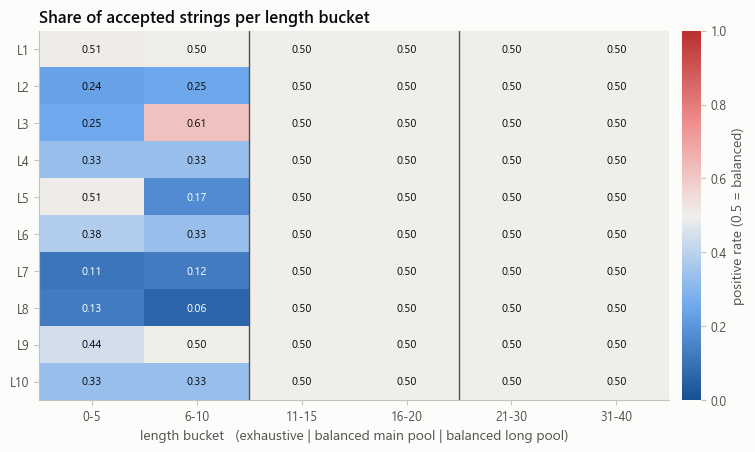

In [10]:
fig, ax = plt.subplots(figsize=(8.6, 4.8))
im = ax.imshow(balance.to_numpy(), cmap=viz.DIVERGING_CMAP, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(bucket_order)), bucket_order)
ax.set_yticks(range(len(balance.index)), balance.index)
ax.grid(False)
for i in range(balance.shape[0]):
    for j in range(balance.shape[1]):
        v = balance.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v - 0.5) > 0.3 else viz.INK)
ax.axvline(1.5, color=viz.INK_SECONDARY, linewidth=1)
ax.axvline(3.5, color=viz.INK_SECONDARY, linewidth=1)
ax.set_title("Share of accepted strings per length bucket")
ax.set_xlabel("length bucket   (exhaustive | balanced main pool | balanced long pool)")
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("positive rate (0.5 = balanced)")
cbar.outline.set_visible(False)
print(viz.savefig(fig, "01_class_balance_by_bucket"))
plt.show()

The exhaustive buckets show each language's natural ratio: L7 and L8 have few short positives, L3 becomes
mostly positive by length 10. From length 11 on, every bucket is exactly balanced.

D:\submission-bc\toc\artifacts\figures\01_length_distribution.png


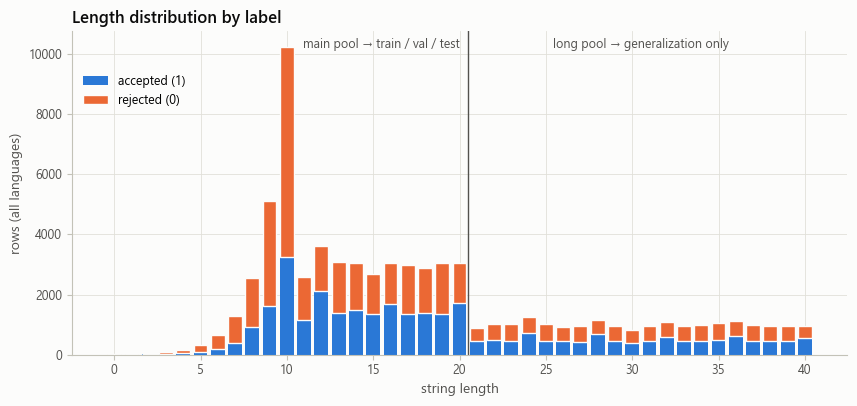

length,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,...,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40
label,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,5,15,29,56,101,220,438,879,1626,3504,6990,1419,1497,1684,1589,...,480,514,442,515,437,491,481,502,534,561,491,537,505,497,401
1,5,5,11,24,59,100,202,401,934,1616,3250,1166,2110,1388,1471,...,453,426,701,454,398,451,603,450,464,485,614,459,447,467,560


In [11]:
by_len = df.groupby(["length", "label"]).size().unstack(fill_value=0).reindex(range(0, 41), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.2))
x = by_len.index.to_numpy()
ax.bar(x, by_len[1], width=0.8, color=viz.CLASS_COLORS[1], label="accepted (1)")
ax.bar(x, by_len[0], width=0.8, bottom=by_len[1], color=viz.CLASS_COLORS[0], label="rejected (0)", edgecolor=viz.SURFACE, linewidth=1)
ax.axvline(20.5, color=viz.INK_SECONDARY, linewidth=1)
ax.text(15.5, ax.get_ylim()[1] * 0.95, "main pool → train / val / test", ha="center", color=viz.INK_SECONDARY, fontsize=9)
ax.text(30.5, ax.get_ylim()[1] * 0.95, "long pool → generalization only", ha="center", color=viz.INK_SECONDARY, fontsize=9)
ax.set_xlabel("string length")
ax.set_ylabel("rows (all languages)")
ax.set_title("Length distribution by label")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.9))
print(viz.savefig(fig, "01_length_distribution"))
plt.show()
display(by_len.T)

Exhaustive enumeration doubles the row count with every extra symbol up to length 10. Beyond that, each
main-pool length gets about 300 strings per language, and each long-pool length about 100.

generation_strategy,exhaustive,structured_run,dfa_uniform_positive,hard_negative_edit,dfa_uniform_negative,near_miss_positive_edit,structured_repeat,structured_palindrome
language_id,,,,,,,,
L1,2047,178,1876,1000,1250,374,134,188
L2,2047,103,1876,1000,1250,374,135,262
L3,2047,123,1876,1000,1250,374,138,239
L4,2047,173,1876,1000,1250,374,128,199
L5,2047,136,1958,1000,1250,292,179,185
L6,2047,162,1876,1000,1250,374,124,214
L7,2047,120,1876,1000,1250,374,113,267
L8,2047,164,1876,1000,1250,374,127,209
L9,2047,132,1876,1000,1250,374,121,247


D:\submission-bc\toc\artifacts\figures\01_generation_strategies.png


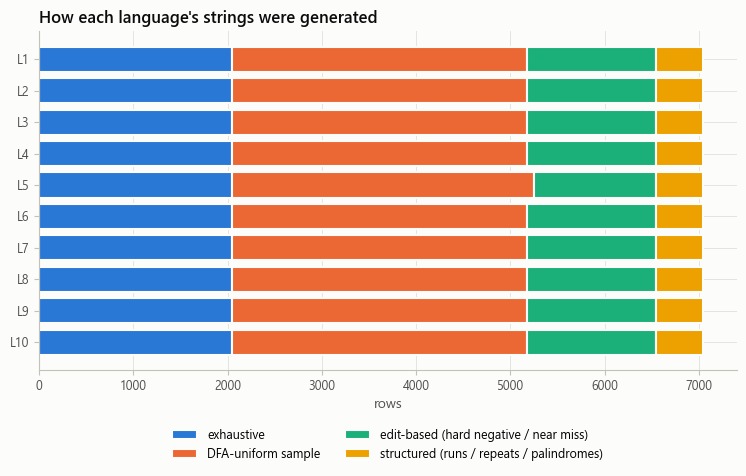

In [12]:
families = {
    "exhaustive": "exhaustive",
    "dfa_uniform_positive": "DFA-uniform sample",
    "dfa_uniform_negative": "DFA-uniform sample",
    "hard_negative_edit": "edit-based (hard negative / near miss)",
    "near_miss_positive_edit": "edit-based (hard negative / near miss)",
    "structured_run": "structured (runs / repeats / palindromes)",
    "structured_repeat": "structured (runs / repeats / palindromes)",
    "structured_palindrome": "structured (runs / repeats / palindromes)",
}
strategy_table = df.groupby(["language_id", "generation_strategy"], sort=False).size().unstack(fill_value=0)
display(strategy_table)
fam = df.assign(family=df.generation_strategy.map(families)).groupby(["language_id", "family"], sort=False).size().unstack(fill_value=0)
fam = fam[list(dict.fromkeys(families.values()))]
fig, ax = plt.subplots(figsize=(9, 4.4))
left = np.zeros(len(fam))
for k, col in enumerate(fam.columns):
    ax.barh(fam.index, fam[col], left=left, color=viz.CATEGORICAL[k], label=col, edgecolor=viz.SURFACE, linewidth=1.5)
    left += fam[col].to_numpy()
ax.invert_yaxis()
ax.set_xlabel("rows")
ax.set_title("How each language's strings were generated")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
print(viz.savefig(fig, "01_generation_strategies"))
plt.show()

In [13]:
dups = report["duplicates_removed"]
print(f"Duplicate candidates discarded during generation: {dups['total']:,}")
display(pd.DataFrame(dups["per_strategy"]).T.fillna(0).astype(int))

Duplicate candidates discarded during generation: 3,430


,structured_palindrome,structured_run,structured_repeat,near_miss_positive_edit,dfa_uniform_positive,hard_negative_edit,dfa_uniform_negative
L1,11,67,84,1,30,15,17
L2,13,30,101,5,45,16,10
L3,8,38,72,0,11,46,36
L4,9,98,150,2,27,7,13
L5,19,158,281,3,164,10,6
L6,10,58,94,2,31,11,16
L7,33,29,69,5,105,12,6
L8,141,185,296,7,173,20,8
L9,11,73,83,1,13,36,19
L10,16,82,128,0,35,10,9


## 6. Save and verify the files

In [14]:
written = save_dataset(df)

# Round-trip: reload through the project's single loader and compare cell by cell.
back = load_dataset(DATASET_CSV)
assert back.equals(df), "CSV round-trip changed the data"
assert (back.string == "").sum() == len(LANGUAGES), "empty strings must survive the round-trip"
assert all(LANGUAGES[l].dfa.accepts(s) == bool(y) for l, s, y in zip(back.language_id, back.string, back.label))
if DATASET_PARQUET.exists():
    pq = pd.read_parquet(DATASET_PARQUET)
    assert (pq.astype(str).to_numpy() == df.astype(str).to_numpy()).all()

write_json(report, DATA_DIR / "dataset_report.json")
(DATA_DIR / "dataset_report.md").write_text(report_markdown(report), encoding="utf-8")

outputs = [*written, DATA_DIR / "dataset_report.json", DATA_DIR / "dataset_report.md"]
outputs += sorted((ROOT / "artifacts" / "figures").glob("01_*.png"))
for p in outputs:
    assert p.exists() and p.stat().st_size > 0, p
    print(f"{p.relative_to(ROOT).as_posix():45s} {p.stat().st_size / 1024:9.1f} KB")

data/dataset.csv                                 4840.0 KB
data/dataset.parquet                              568.7 KB
data/dataset_report.json                           23.1 KB
data/dataset_report.md                              2.5 KB
artifacts/figures/01_class_balance_by_bucket.png      62.0 KB
artifacts/figures/01_generation_strategies.png      37.7 KB
artifacts/figures/01_length_distribution.png       36.1 KB


In [15]:
main_n, long_n = int((df.split_hint == "main").sum()), int((df.split_hint == "long").sum())
display(Markdown(f'''
### Summary
* **{len(df):,} labelled strings** for {df.language_id.nunique()} languages ({len(df) // df.language_id.nunique():,} per language).
* Main pool (lengths 0–20): **{main_n:,}** strings · long generalization pool (lengths 21–40): **{long_n:,}** strings.
* Overall positive rate {df.label.mean():.3f}; every sampled bucket is exactly balanced.
* {report["duplicates_removed"]["total"]:,} duplicate candidates were discarded; the final file has no duplicate `(language_id, string)` pair.
* Every label was verified against the NFA, the subset-construction DFA, Thompson's ε-NFA, a Python predicate and Python's `re`.
'''))


### Summary
* **70,470 labelled strings** for 10 languages (7,047 per language).
* Main pool (lengths 0–20): **50,470** strings · long generalization pool (lengths 21–40): **20,000** strings.
* Overall positive rate 0.449; every sampled bucket is exactly balanced.
* 3,430 duplicate candidates were discarded; the final file has no duplicate `(language_id, string)` pair.
* Every label was verified against the NFA, the subset-construction DFA, Thompson's ε-NFA, a Python predicate and Python's `re`.


## 7. Conclusions

* The ground-truth automata are verified three ways: subset construction, three independent minimizers
  that agree up to isomorphism, and product-construction equivalence proofs. Each minimal DFA matches its
  hand-derived state count.
* The dataset combines complete coverage of short strings with balanced, boundary-heavy sampling of longer
  strings. Hard negatives and near-miss positives are one or two edits away from the opposite class.
* The `long` pool (lengths 21–40) is kept separate. Notebook 02 never trains on it and uses it only to
  measure how well each approach generalizes to longer strings.

Next: `02_eda_models_automata.ipynb` — splits, EDA, ML pipelines, and automata extracted from every
pipeline with L*.